
# PyTorch MLP on Synthetic Data: $y = x_1 \times x_2$

This notebook generates a 2D synthetic dataset where the target is
y = x_1 * x_2 .<br>  Then trains a small MLP regressor.


## 1) Setup

In [1]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cpu')

## 2) Generate synthetic data (2000 samples)

In [2]:


def make_y_equals_x1_times_x2(n_samples=2000, x_range=3.0, noise_std=0.2, dtype=torch.float32):
    X = torch.empty(n_samples, 2, dtype=dtype).uniform_(-x_range, x_range)

    #want to add noise? This means its harder to train a model to predict the target. This is more realistic for real world data.
    noise = noise_std * torch.randn(n_samples, dtype=dtype)
    y = X[:, 0] * X[:, 1] + noise
    # y = X[:, 0] * X[:, 1]
    return X, y

X, y = make_y_equals_x1_times_x2(n_samples=2000, x_range=3.0, noise_std=0.2)
X.shape, y.shape, X[:3], y[:3]


(torch.Size([2000, 2]),
 torch.Size([2000]),
 tensor([[ 2.2936,  2.4900],
         [-0.7028,  2.7558],
         [-0.6573,  0.6054]]),
 tensor([ 5.2164, -1.6762, -0.5170]))

### See what data looks like

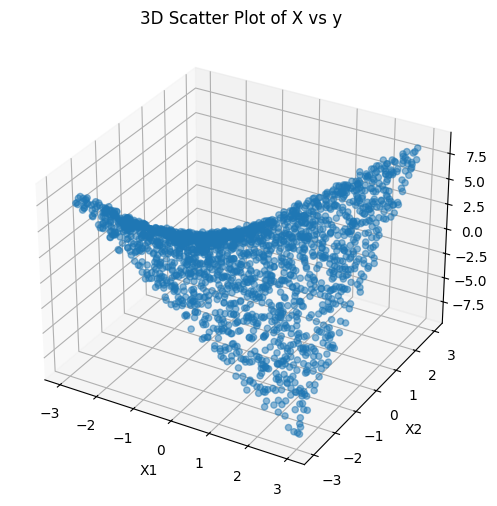

In [3]:
# %matplotlib widget
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

#force to CPU for plotting, since matplotlib doesn't support GPU tensors
ax.scatter(X[:, 0].cpu(), X[:, 1].cpu(), y.cpu(), alpha=0.5)
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('y')
ax.set_title('3D Scatter Plot of X vs y')
plt.show()

### OPTIONAL: use Tensorboard embeddings projector to plot data

Tensorboard comes in handy for a bunch of stuff, see <a href="https://docs.pytorch.org/tutorials/recipes/recipes/tensorboard_with_pytorch.html">How to use TensorBoard with PyTorch</a>

In [4]:
#for tensorboard embedding projector
import torch
from torch.utils.tensorboard import SummaryWriter
import numpy as np

# A log directory to store the events.
log_dir = "log_dir/custom_embeddings_torch"

# 1. Prepare your data (replace with your own).
vectors = torch.cat([X, torch.zeros(X.shape[0], 1, device=X.device)], dim=1)
vectors[:,2] = y
metadata = [f"label_{i}" for i in range(len(vectors))]

print (vectors.shape)  # Should be (num_samples, embedding_dim)
print(len(metadata))

# 2. Create a SummaryWriter and add the embedding.
writer = SummaryWriter(log_dir)
writer.add_embedding(vectors, metadata=metadata)
writer.close()

print(f"Embedding data logged to {log_dir}")

#to call up tensorboard, run following in terminal,
# from directory this notebook is in, choose projector
# tensorboard --logdir=logs


2026-09-16 12:45:11.714830: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


torch.Size([2000, 3])
2000
Embedding data logged to log_dir/custom_embeddings_torch


## 3) Train/Val split and feature scaling

Note that there are no for loops, vectorized operations only
calculate trainmean and trainstd on train set only, then subtract trainmean and divide by trainstandard on train and val sets


In [5]:
# Shuffle the dataset and split into training and validation sets
# Why shuffle the dataset?  Because the data is generated in a specific order.  If we dont shuffle we might end up with a validation set that contains values the train set has never seen, which is not a good idea.  We want to make sure the train and validation sets are representative of the same distribution.
idx = torch.randperm(len(X))
n_train = int(0.8 * len(X))
tr_idx, va_idx = idx[:n_train], idx[n_train:]

# Select training and validation data
Xtr, ytr = X[tr_idx], y[tr_idx]
Xva, yva = X[va_idx], y[va_idx]

# Compute mean and std from training features for normalization
# The 0 means compute along the 0th dimension (i.e. for each column/feature)
x_mean, x_std = Xtr.mean(0), Xtr.std(0)

#normalize features (you will do this a lot in future assignments)
Xtr_n = (Xtr - x_mean) / x_std
Xva_n = (Xva - x_mean) / x_std

# Create DataLoaders for training and validation sets
train_loader = DataLoader(TensorDataset(Xtr_n, ytr), batch_size=128, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xva_n, yva), batch_size=256, shuffle=False)

# Show shapes for sanity check
Xtr_n.shape, ytr.shape, Xva_n.shape, yva.shape


(torch.Size([1600, 2]),
 torch.Size([1600]),
 torch.Size([400, 2]),
 torch.Size([400]))

## 4) Define the MLP model

torch.nn has the classes necessary for building Neural Networks 

In [6]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    """
    A simple fully-connected neural network (Multi-Layer Perceptron).

    Inputs:
      - in_dim:  number of input features per example (e.g., 2 if x = [x1, x2])
      - hidden:  sizes of the two hidden layers (tuple of ints)
      - out_dim: number of outputs (1 for regression; >=2 for multi-class logits)

    Expected input shape to forward(x):
      - x: [batch_size, in_dim]
    """

    def __init__(self, in_dim=2, hidden=(64, 64), out_dim=1):
        super().__init__()  # initialize nn.Module internals

        # Fully-connected (linear) layers: y = x @ W^T + b        
        self.fc1 = nn.Linear(in_dim, hidden[0]) # fc1 maps from in_dim -> hidden[0]
        self.fc2 = nn.Linear(hidden[0], hidden[1]) # fc2 maps from hidden[0] -> hidden[1]
        self.fc3 = nn.Linear(hidden[1], out_dim) # fc3 maps from hidden[1] -> out_dim (final predictions/logits)

        # Nonlinearity: ReLU(x) = max(0, x). Adds capacity to learn nonlinear patterns.
        self.relu = nn.ReLU()

    def forward(self, x):
        """
        Forward pass: how the input tensor flows through the layers.

        x: [batch_size, in_dim]
        returns:
          - if out_dim == 1: [batch_size]  (due to squeeze at the end)
          - if out_dim  > 1: [batch_size, out_dim]
        """
        # Layer 1: linear transform, then ReLU
        x = self.relu(self.fc1(x))  # -> [batch_size, hidden[0]]

        # Layer 2: linear transform, then ReLU
        x = self.relu(self.fc2(x))  # -> [batch_size, hidden[1]]

        # Output layer: linear transform to out_dim (no activation here for regression or logits)
        x = self.fc3(x)             # -> [batch_size, out_dim]

        # If we're doing single-output regression (out_dim == 1), remove the last dimension
        # so shape becomes [batch_size] instead of [batch_size, 1].
        # If you prefer to keep shape [batch_size, 1], delete the squeeze.
        return x.squeeze(-1)


## 5) Train and evaluate functions

This is called a training loop. Something very similar is used when training any model

In [7]:
# start here 9/16/26
import torch


@torch.no_grad()  # Disable gradient tracking inside this function (saves memory/compute)
def evaluate(model, loader, criterion, device):
    """
    Puts the model in evaluation mode and computes the average loss
    over all batches in `loader`.

    Args:
        model:     a torch.nn.Module
        loader:    DataLoader for validation/test data
        criterion: loss function (e.g., nn.MSELoss())
        device:    'cuda' or 'cpu' device to run on

    Returns:
        avg_loss (float): mean loss over the dataset
    """
    model.eval()          # turn off dropout / use running stats for batchnorm, etc., neither of which are covered in this class (we are time constrained) :(
    total_loss, total_n = 0.0, 0

    for xb, yb in loader:
        # Move the current batch to the right device
        xb, yb = xb.to(device), yb.to(device)

        # Forward pass only (no grad because of @torch.no_grad)
        preds = model(xb)
        loss = criterion(preds, yb)

        # Accumulate *sum* of losses so we can compute dataset average
        total_loss += loss.item() * xb.size(0)  # multiply by batch size
        total_n    += xb.size(0)

    return total_loss / total_n  # average loss over all examples


def train(model, train_loader, val_loader, criterion, optimizer, device, epochs=200, log_every=20):
    """
    Standard training loop with per-epoch validation.

    Args:
        model:        a torch.nn.Module
        train_loader: DataLoader for training data
        val_loader:   DataLoader for validation data
        criterion:    loss function (e.g., nn.MSELoss())
        optimizer:    torch.optim optimizer (e.g., Adam)
        device:       'cuda' or 'cpu'
        epochs:       number of training epochs
        log_every:    how often to print progress (in epochs)

    Returns:
        train_losses (list[float]): average train MSE for each epoch
        val_losses   (list[float]): average val MSE for each epoch
    """
    train_losses = []  # store one avg train loss per epoch, for plotting later
    val_losses = []    # store one avg val loss per epoch, for plotting later

    for epoch in range(1, epochs + 1):
        model.train()                # enable training behavior (dropout, batchnorm updates, etc.)
        running_loss, total_n = 0.0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            # 1) Reset gradients from the previous step
            optimizer.zero_grad(set_to_none=True)
            #    set_to_none=True can be a tiny memory/perf win vs. zeroing to 0.0

            # 2) Forward pass: compute predictions and loss
            preds = model(xb)
            loss  = criterion(preds, yb)  # e.g., MSE loss

            # 3) Backward pass: compute gradients w.r.t. parameters
            loss.backward()

            # 4) Update parameters using the optimizer, this will 
            # subtract a small bit (lr*grad) of the gradient from each parameter
            optimizer.step()

            # Track running training loss (sum over all samples)
            running_loss += loss.item() * xb.size(0)
            total_n      += xb.size(0)

        # Average train loss this epoch
        train_mse = running_loss / total_n

        # Evaluate on the validation set (no-grad inside)
        val_mse = evaluate(model, val_loader, criterion, device)

        # Save losses for plotting
        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # Print progress
        if (epoch % log_every == 0) or (epoch == 1):
            print(f"epoch {epoch:03d} | train MSE {train_mse:.4f} | val MSE {val_mse:.4f}")

    return train_losses, val_losses


## 6) Loss & optimizer

torch.nn also has the loss functions and optimizers for training

In [8]:
model = MLP(in_dim=2, hidden=(12, 12)).to(device)
print(model)

lr=.01
criterion = nn.MSELoss()  #dont need to create your own loss function, pytorch has many built in
optimizer = torch.optim.SGD(model.parameters(), lr=lr)    #tracks the parameters of model and updates them
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)  #faster optimizer



MLP(
  (fc1): Linear(in_features=2, out_features=12, bias=True)
  (fc2): Linear(in_features=12, out_features=12, bias=True)
  (fc3): Linear(in_features=12, out_features=1, bias=True)
  (relu): ReLU()
)


In [9]:
print(model)

# the actual number of learnable scalars (weights + biases added up)
# For MLP(in_dim=2, hidden=(12,12)) that's:
# - fc1: 2×12 + 12 = 36
# - fc2: 12×12 + 12 = 156
# - fc3: 12×1 + 1 = 13
# the total number of learnable parameters is 36 + 156 + 13 = 205.
sum(p.numel() for p in model.parameters())

MLP(
  (fc1): Linear(in_features=2, out_features=12, bias=True)
  (fc2): Linear(in_features=12, out_features=12, bias=True)
  (fc3): Linear(in_features=12, out_features=1, bias=True)
  (relu): ReLU()
)


205

## 7) Train Model

In [ ]:
train_losses, val_losses = train(model, train_loader, val_loader, criterion, optimizer, device, epochs=300, log_every=5)

epoch 001 | train MSE 8.8623 | val MSE 8.4644
epoch 005 | train MSE 7.7288 | val MSE 7.1849


epoch 010 | train MSE 3.1823 | val MSE 2.6796


epoch 015 | train MSE 0.7402 | val MSE 0.6876
epoch 020 | train MSE 0.4284 | val MSE 0.4257


epoch 025 | train MSE 0.3387 | val MSE 0.3372


epoch 030 | train MSE 0.2943 | val MSE 0.2883
epoch 035 | train MSE 0.2588 | val MSE 0.2412


...

epoch 435 | train MSE 0.0548 | val MSE 0.0539
epoch 440 | train MSE 0.0544 | val MSE 0.0541
epoch 445 | train MSE 0.0541 | val MSE 0.0536


epoch 450 | train MSE 0.0546 | val MSE 0.0558
epoch 455 | train MSE 0.0535 | val MSE 0.0544
epoch 460 | train MSE 0.0543 | val MSE 0.0538


epoch 465 | train MSE 0.0534 | val MSE 0.0550
epoch 470 | train MSE 0.0541 | val MSE 0.0535
epoch 475 | train MSE 0.0536 | val MSE 0.0552


epoch 480 | train MSE 0.0541 | val MSE 0.0555
epoch 485 | train MSE 0.0525 | val MSE 0.0632
epoch 490 | train MSE 0.0528 | val MSE 0.0540


epoch 495 | train MSE 0.0535 | val MSE 0.0541
epoch 500 | train MSE 0.0527 | val MSE 0.0532


### Plot train vs. validation loss curves

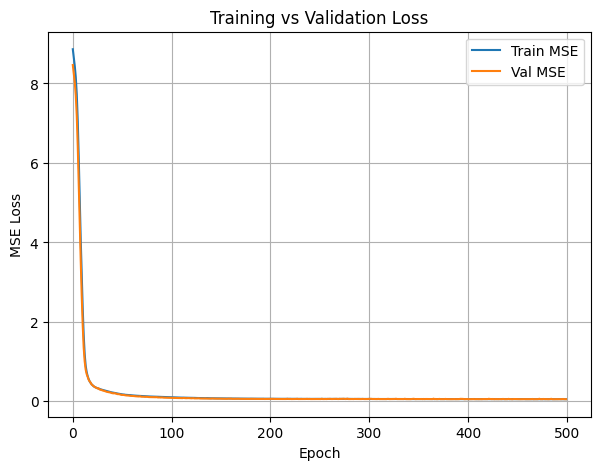

In [11]:
# %matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.plot(train_losses, label='Train MSE')
plt.plot(val_losses, label='Val MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


<mark>So train and val loss keep dropping.  What happened to the rising val loss?  That happens when the model starts to overfit on the training data (memorizing the training dataset).  This model has 205 learnable parameters.  Thats probably not enough capacity to memorize data
<br>
Show train verses validation loss plot on board, indicate when validation loss starts to rise you should stop training

## 8) Sample predictions (sanity check)

In [12]:

@torch.no_grad()    # indicates we are not training a model
                    # Disables the PyTorch autograd engine within this scope, preventing the computation and storage of gradients.
                    # Significantly reduces memory consumption and increases computation speed
def preview_predictions(model, X_raw, y_true):
    model.eval()    # no effect on this model, on more complex nets will turn off dropout, etc.
    preds = model(X_raw.to(device))  #get predictions for this batch
    for i in range(len(X_raw)):
        x1, x2 = X_raw[i].tolist()
        print(f"x=({x1:+.3f},{x2:+.3f})  y_true={y_true[i]:+.3f}  y_pred={preds[i]:+.3f} ")

print("Validation set preview:")
preview_predictions(model, Xva_n[:5], yva[:5])


Validation set preview:
x=(-0.536,-1.452)  y_true=+2.136  y_pred=+2.188 
x=(-0.062,+1.152)  y_true=-0.471  y_pred=-0.370 
x=(-0.475,-0.699)  y_true=+1.147  y_pred=+0.993 
x=(+0.362,+1.173)  y_true=+1.284  y_pred=+1.273 
x=(-1.674,+1.476)  y_true=-7.105  y_pred=-6.748 


### Plot actuals verses predicted (if model is accurate they should be roughly equal)

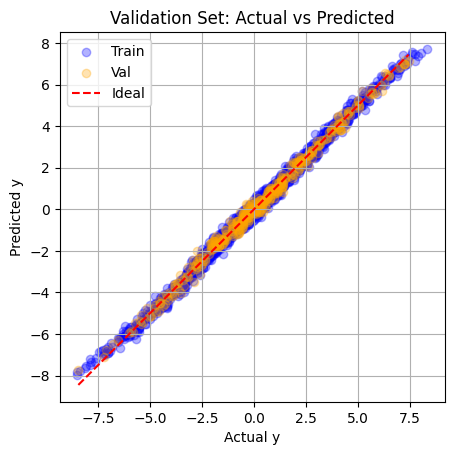

In [13]:
import matplotlib.pyplot as plt
model.to('cpu')  #move model to cpu for plotting
model.eval()
with torch.no_grad():
    preds_tr = model(Xtr_n.to('cpu'))
    preds_val= model(Xva_n.to('cpu'))

plt.scatter(ytr, preds_tr, alpha=0.3, color='blue', label='Train')
plt.scatter(yva, preds_val, alpha=0.3, color='orange', label='Val')
plt.plot([yva.min(), yva.max()], [yva.min(), yva.max()], 'r--', label='Ideal')
plt.xlabel('Actual y')
plt.ylabel('Predicted y')
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Validation Set: Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()

## 8) Checkpointing (Saving and Loading a model)

In [14]:
# ---------------------------
# Saving a training checkpoint
# ---------------------------

# torch.save can write (almost) any Python object to disk.
# Common practice: save a DICTIONARY with everything you’ll need to resume training later.
torch.save({
    "model": model.state_dict(),      # model "weights" (parameters as plain tensors)
    "opt": optimizer.state_dict()     # optimizer state (e.g., Adam's moment estimates)
}, "ckpt_demo.pt")

print("Saved to ckpt_demo.pt")

# ---------------------------
# Loading a training checkpoint
# ---------------------------

# torch.load reads the file back into memory.
# map_location=device makes sure tensors are moved to the right device (e.g., "cpu" or "cuda").
ckpt = torch.load("ckpt_demo.pt", map_location=device)

# Put the saved weights back into the model.
# Note: the model architecture in code must MATCH the one that created the checkpoint.
model.load_state_dict(ckpt["model"])

# Restore the optimizer’s internal state so you can continue training seamlessly
# (keeps momentum/Adam moments, etc.).
optimizer.load_state_dict(ckpt["opt"])

print("Reloaded checkpoint.")



Saved to ckpt_demo.pt
Reloaded checkpoint.


## 9) (Optional) Try things


- Change hidden sizes `(32, 32)` or `(128, 128)` and compare validation MSE.
- change learning rate to 0.5, notice model does not converge.  it is 'jumping' past the solution because each param is being adjusted too much


## 10) Demo: Overfitting (val loss rises while train loss falls)

The model we trained above (`hidden=(12,12)`) never overfits: it's tiny relative to the ~1600 training points, and the true function (`x1*x2`) is smooth and easy to fit. With enough data and a model too small to memorize noise, train and val loss both settle near the *irreducible noise floor* (`noise_std**2 = 0.04`) instead of diverging.

To actually **see** overfitting, we need the opposite setup: a training set too small to pin down the true function, and a model big enough to memorize it anyway. Below we reuse the same `MLP` class and `train`/`evaluate` functions, but:
- shrink the training set to just 12 examples,
- keep the full validation set (400 examples) for a fair comparison,
- give the model much more capacity (`hidden=(256,256)`),
- train for many more epochs.

Watch for: train MSE drops toward ~0 (the model memorizes the 12 noisy points exactly), while val MSE drops for a while and then **turns around and rises** as the model's fit gets increasingly tailored to quirks of those 12 points instead of the true `x1*x2` surface.

**Note:** the rise is real but small compared to how far val loss drops in the first few epochs, so a plain plot of the whole curve visually squashes it flat near the bottom. The plotting cell below zooms in after the best epoch specifically to make it visible.

In [15]:
# --- Overfitting demo: tiny training set + oversized model ---
torch.manual_seed(0)

# Shrink the training set drastically (keep the same normalization/val set from cell above for a fair comparison)
n_overfit = 12
Xtr_small = Xtr_n[:n_overfit]
ytr_small = ytr[:n_overfit]

overfit_train_loader = DataLoader(TensorDataset(Xtr_small, ytr_small), batch_size=n_overfit, shuffle=True)
overfit_val_loader   = val_loader  # reuse the full 400-example validation set from earlier

# A much bigger model -- plenty of capacity to memorize just 12 noisy points
overfit_model = MLP(in_dim=2, hidden=(256, 256)).to(device)

overfit_criterion = nn.MSELoss()
# A smaller lr than the main run's default: slows convergence just enough that the model
# passes through a decent generalizing fit before it fully memorizes the 12 points,
# so the dip-then-rise shows up clearly instead of happening in the first few epochs.
overfit_optimizer = torch.optim.Adam(overfit_model.parameters(), lr=5e-4)

overfit_train_losses, overfit_val_losses = train(
    overfit_model, overfit_train_loader, overfit_val_loader,
    overfit_criterion, overfit_optimizer, device,
    epochs=1200, log_every=100
)


epoch 001 | train MSE 7.2897 | val MSE 8.0661


epoch 100 | train MSE 0.1105 | val MSE 2.5385


epoch 200 | train MSE 0.0058 | val MSE 1.5946


epoch 300 | train MSE 0.0018 | val MSE 1.5837


epoch 400 | train MSE 0.0005 | val MSE 1.5994


...

epoch 800 | train MSE 0.0000 | val MSE 1.6297


epoch 900 | train MSE 0.0000 | val MSE 1.6310


epoch 1000 | train MSE 0.0000 | val MSE 1.6315


epoch 1100 | train MSE 0.0000 | val MSE 1.6316


epoch 1200 | train MSE 0.0000 | val MSE 1.6312


### Plot: train MSE keeps falling, val MSE rises

Best val MSE:  1.5727 at epoch 169
Final val MSE: 1.6312 at epoch 1200  (+0.0585 above the best -- this is the overfitting)


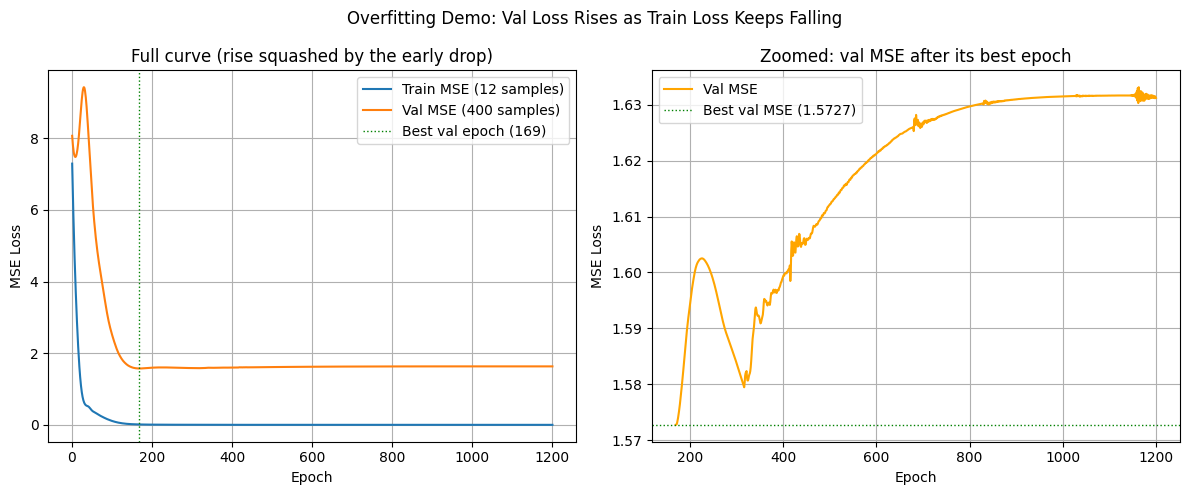

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

epochs_axis = np.arange(1, len(overfit_val_losses) + 1)
best_epoch  = int(np.argmin(overfit_val_losses)) + 1   # epoch numbers start at 1
best_val    = overfit_val_losses[best_epoch - 1]
final_val   = overfit_val_losses[-1]
print(f"Best val MSE:  {best_val:.4f} at epoch {best_epoch}")
print(f"Final val MSE: {final_val:.4f} at epoch {epochs_axis[-1]}  "
      f"(+{final_val - best_val:.4f} above the best -- this is the overfitting)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: the whole picture. The early drop dwarfs the later rise, so the rise looks
# almost flat here -- that's exactly the illusion this section is warning you about.
ax = axes[0]
ax.plot(epochs_axis, overfit_train_losses, label='Train MSE (12 samples)')
ax.plot(epochs_axis, overfit_val_losses, label='Val MSE (400 samples)')
ax.axvline(best_epoch, color='green', linestyle=':', linewidth=1, label=f'Best val epoch ({best_epoch})')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.set_title('Full curve (rise squashed by the early drop)')
ax.legend(); ax.grid(True)

# Right: zoom in on val loss only, starting at the best epoch -- the rise is unmistakable here.
ax = axes[1]
ax.plot(epochs_axis[best_epoch - 1:], overfit_val_losses[best_epoch - 1:], color='orange', label='Val MSE')
ax.axhline(best_val, color='green', linestyle=':', linewidth=1, label=f'Best val MSE ({best_val:.4f})')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss')
ax.set_title('Zoomed: val MSE after its best epoch')
ax.legend(); ax.grid(True)

fig.suptitle('Overfitting Demo: Val Loss Rises as Train Loss Keeps Falling')
plt.tight_layout()
plt.show()


Once val MSE bottoms out and starts climbing, that's the point where you'd want **early stopping**: save a checkpoint whenever val loss hits a new low, and stop training (or restore that checkpoint) once it's clear val loss is on its way back up.

## 11) Demo: ReLU as a no-op (nn.Identity)

What happens if we remove the nonlinearity? Swap every `nn.ReLU()` in the model for `nn.Identity()` (a layer that just returns its input unchanged, i.e. a nop). With no nonlinearity between them, `fc1 -> fc2 -> fc3` collapses mathematically into a single linear layer, no matter how many "hidden" layers there are. So this model can only represent a **linear** function of `x1, x2`, and should struggle to fit `y = x1 * x2`, which is not linear.

In [17]:
# --- No-op activation demo: same MLP class, ReLU replaced with nn.Identity() ---
norelu_model = MLP(in_dim=2, hidden=(12, 12)).to(device)
norelu_model.relu = nn.Identity()  # <-- the only change: ReLU becomes a nop
print(norelu_model)

norelu_criterion = nn.MSELoss()
norelu_optimizer = torch.optim.SGD(norelu_model.parameters(), lr=lr)

norelu_train_losses, norelu_val_losses = train(
    norelu_model, train_loader, val_loader,
    norelu_criterion, norelu_optimizer, device,
    epochs=500, log_every=50
)

MLP(
  (fc1): Linear(in_features=2, out_features=12, bias=True)
  (fc2): Linear(in_features=12, out_features=12, bias=True)
  (fc3): Linear(in_features=12, out_features=1, bias=True)
  (relu): Identity()
)
epoch 001 | train MSE 8.8379 | val MSE 8.3532


epoch 050 | train MSE 8.6965 | val MSE 8.4152


epoch 100 | train MSE 8.7025 | val MSE 8.4277


epoch 150 | train MSE 8.6947 | val MSE 8.4216


epoch 200 | train MSE 8.6919 | val MSE 8.4020


...

epoch 300 | train MSE 8.6921 | val MSE 8.4114


epoch 350 | train MSE 8.6932 | val MSE 8.4192


epoch 400 | train MSE 8.6935 | val MSE 8.4101


epoch 450 | train MSE 8.6914 | val MSE 8.4143


epoch 500 | train MSE 8.6927 | val MSE 8.4072


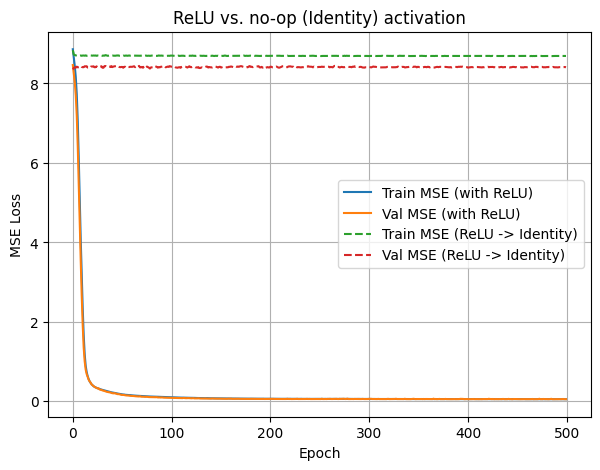

Final val MSE with ReLU:     0.0532
Final val MSE with Identity: 8.4072


In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.plot(train_losses, label='Train MSE (with ReLU)')
plt.plot(val_losses, label='Val MSE (with ReLU)')
plt.plot(norelu_train_losses, '--', label='Train MSE (ReLU -> Identity)')
plt.plot(norelu_val_losses, '--', label='Val MSE (ReLU -> Identity)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('ReLU vs. no-op (Identity) activation')
plt.legend()
plt.grid(True)
plt.show()

print(f"Final val MSE with ReLU:     {val_losses[-1]:.4f}")
print(f"Final val MSE with Identity: {norelu_val_losses[-1]:.4f}")